In [ ]:
from google.colab import files
uploaded = files.upload()

Saving seeds_dataset.csv to seeds_dataset (1).csv


In [ ]:
 #2.feature scaling

In [ ]:

import numpy as np
column_names = [
    'area', 'perimeter', 'compactness', 'length_of_kernel',
    'width_of_kernel', 'asymmetry_coefficient', 'length_of_kernel_groove', 'class'
]

df = pd.read_csv('seeds_dataset.csv', sep='\s+', names=column_names)

print("--- Dataset Info ---")
df.info()
print("\n--- Missing Values ---")
print(df.isnull().sum())
print("\n--- First 5 Rows ---")
display(df.head())

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   area                     210 non-null    float64
 1   perimeter                210 non-null    float64
 2   compactness              210 non-null    float64
 3   length_of_kernel         210 non-null    float64
 4   width_of_kernel          210 non-null    float64
 5   asymmetry_coefficient    210 non-null    float64
 6   length_of_kernel_groove  210 non-null    float64
 7   class                    210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB

--- Missing Values ---
area                       0
perimeter                  0
compactness                0
length_of_kernel           0
width_of_kernel            0
asymmetry_coefficient      0
length_of_kernel_groove    0
class                      0
dtype: int64

--- First 5 Ro

<>:11: SyntaxWarning: invalid escape sequence '\s'
<>:11: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1834/2276120088.py:11: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv('seeds_dataset.csv', sep='\s+', names=column_names)


,area,perimeter,compactness,length_of_kernel,width_of_kernel,asymmetry_coefficient,length_of_kernel_groove,class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [ ]:
from sklearn.preprocessing import StandardScaler

features = ['area', 'perimeter', 'compactness', 'length_of_kernel',
            'width_of_kernel', 'asymmetry_coefficient', 'length_of_kernel_groove']
X = df[features]
y_true = df['class']


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
#3.K Means

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = [2, 3, 4, 5]
inertia_scores = []
silhouette_scores = []
random_seed = 42

for k in k_values:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=random_seed, n_init=10)
    kmeans.fit(X_scaled)
    inertia_scores.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

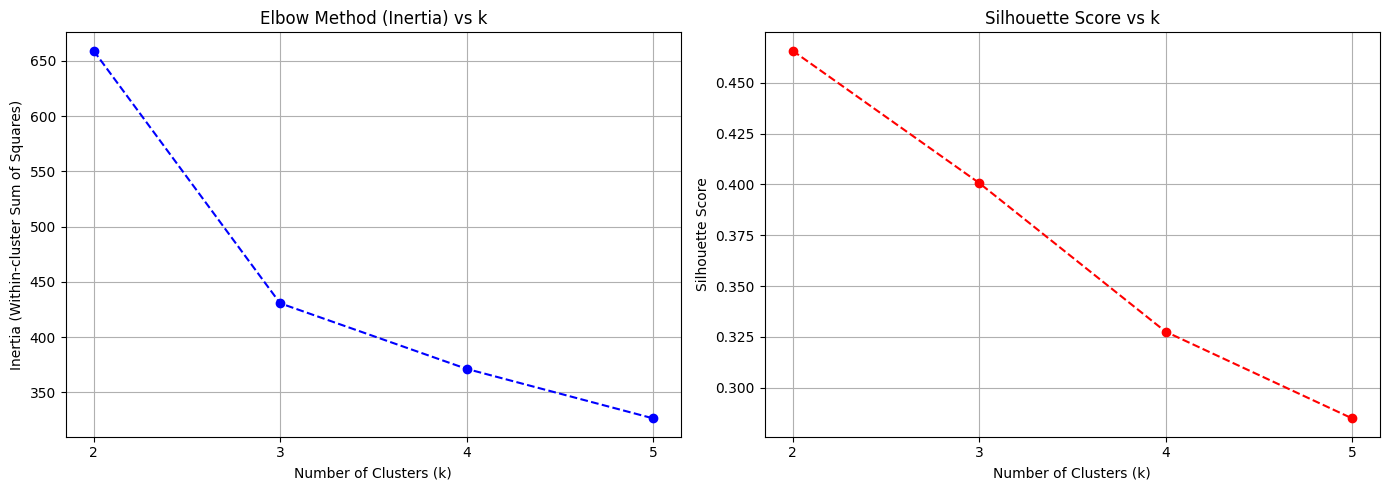

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Plot Inertia
plt.subplot(1, 2, 1)
plt.plot(k_values, inertia_scores, marker='o', color='b', linestyle='--')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-cluster Sum of Squares)')
plt.title('Elbow Method (Inertia) vs k')
plt.xticks(k_values)
plt.grid(True)

# Plot Silhouette Score
plt.subplot(1, 2, 2)
plt.plot(k_values, silhouette_scores, marker='o', color='r', linestyle='--')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs k')
plt.xticks(k_values)
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Create a structured comparison DataFrame
metrics_df = pd.DataFrame({
    'Number of Clusters (k)': k_values,
    'Inertia (Lower = Better)': inertia_scores,
    'Silhouette Score (Higher = Better)': silhouette_scores
})

display(metrics_df)

,Number of Clusters (k),Inertia (Lower = Better),Silhouette Score (Higher = Better)
0,2,659.171754,0.465772
1,3,430.658973,0.400727
2,4,371.301721,0.327574
3,5,326.513695,0.284930


In [ ]:
4.#PCA

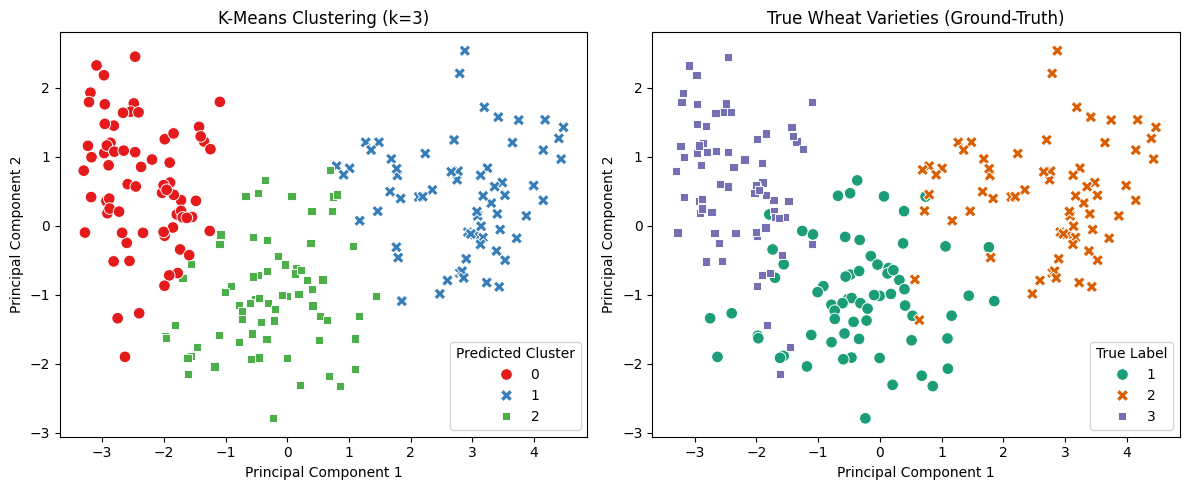

In [ ]:
from sklearn.decomposition import PCA
import seaborn as sns

# Fit optimal model
optimal_k = 3
kmeans_optimal = KMeans(n_clusters=optimal_k, init='k-means++', random_state=random_seed, n_init=10)
cluster_labels = kmeans_optimal.fit_predict(X_scaled)

# Project down to 2 dimensions
pca = PCA(n_components=2, random_state=random_seed)
X_pca = pca.fit_transform(X_scaled)

# Visual comparison of unsupervised clusters vs true varieties
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=cluster_labels, palette='Set1', style=cluster_labels, s=70)
plt.title(f'K-Means Clustering (k={optimal_k})')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Predicted Cluster')

plt.subplot(1, 2, 2)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_true, palette='Dark2', style=y_true, s=70)
plt.title('True Wheat Varieties (Ground-Truth)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='True Label')

plt.tight_layout()
plt.show()

In [ ]:
#5.Post-hoc

In [ ]:
df['Predicted_Cluster'] = cluster_labels

print("--- Cluster Size Summary ---")
print(df['Predicted_Cluster'].value_counts())

print("\n--- Feature Summaries per Predicted Cluster ---")
display(df.groupby('Predicted_Cluster')[features].mean())

print("\n--- Post-Hoc Confusion Table ---")
cross_tab = pd.crosstab(df['class'], df['Predicted_Cluster'], rownames=['True Class'], colnames=['Predicted Cluster'])
display(cross_tab)

--- Cluster Size Summary ---
Predicted_Cluster
0    72
2    71
1    67
Name: count, dtype: int64

--- Feature Summaries per Predicted Cluster ---


,area,perimeter,compactness,length_of_kernel,width_of_kernel,asymmetry_coefficient,length_of_kernel_groove
Predicted_Cluster,,,,,,,
0,11.856944,13.247778,0.848253,5.231750,2.849542,4.742389,5.101722
1,18.495373,16.203433,0.884210,6.175687,3.697537,3.632373,6.041701
2,14.437887,14.337746,0.881597,5.514577,3.259225,2.707341,5.120803



--- Post-Hoc Confusion Table ---


Predicted Cluster,0,1,2
True Class,,,
1,6,2,62
2,0,65,5
3,66,0,4
